##### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("../Data/heart.csv")

##### EDA

In [3]:
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [4]:
df.shape


(920, 16)

In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [6]:
df.columns


Index(['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs',
       'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')

In [7]:
df.describe()


,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [8]:
df.isnull().sum()


id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

In [9]:
numerical_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
df[numerical_cols].isnull().sum()

age          0
trestbps    59
chol        30
thalch      55
oldpeak     62
dtype: int64

In [10]:
for col in numerical_cols:
    df[col].fillna(df[col].median(), inplace=True)

In [11]:
df[numerical_cols].isnull().sum()

age         0
trestbps    0
chol        0
thalch      0
oldpeak     0
dtype: int64

In [12]:
categorical_cols = [ 'sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal', 'ca']

df[categorical_cols].isnull().sum()

sex          0
cp           0
fbs         90
restecg      2
exang       55
slope      309
thal       486
ca         611
dtype: int64

In [13]:
for col in categorical_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

In [14]:
df[categorical_cols].isnull().sum()

sex        0
cp         0
fbs        0
restecg    0
exang      0
slope      0
thal       0
ca         0
dtype: int64

In [15]:
df.duplicated().sum()


np.int64(0)

In [16]:
df['num'] = df['num'].apply(lambda x: 0 if x == 0 else 1)


In [17]:
df['num'].value_counts()

num
1    509
0    411
Name: count, dtype: int64

##### Visualization

<Axes: xlabel='num'>

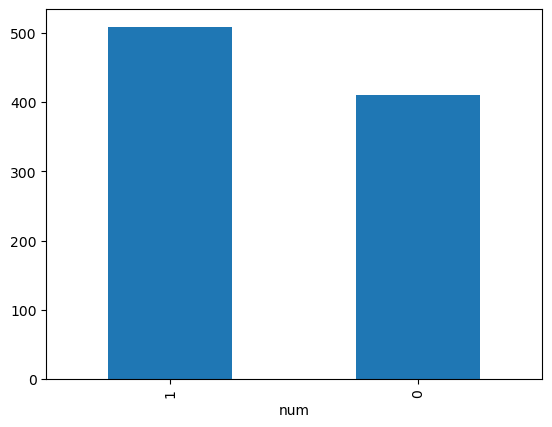

In [18]:
df['num'].value_counts().plot(kind = 'bar')

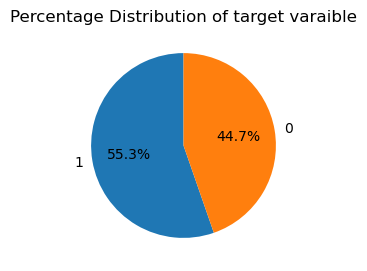

In [19]:
df['num'].value_counts().plot.pie(
    autopct='%1.1f%%', startangle=90, figsize=(3, 3)
)
plt.ylabel('')
plt.title("Percentage Distribution of target varaible")
plt.show()

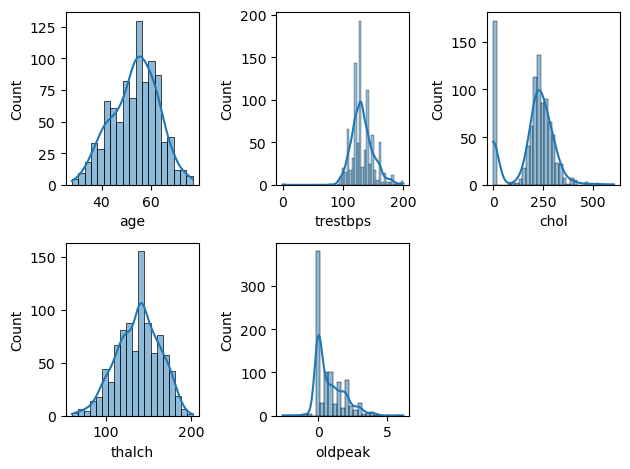

In [20]:
def plotting(var,num):
    plt.subplot(2,3,num)
    sns.histplot(df[var],kde = True)
    
plotting('age',1)
plotting('trestbps',2)
plotting('chol',3)
plotting('thalch',4)
plotting('oldpeak',5)

plt.tight_layout()

In [21]:
ch_mean = df.loc[df['chol'] != 0, 'chol'].mean()
df['chol'] = df['chol'].replace(0,ch_mean)
df['chol'] = df['chol'].round(2)

In [22]:
trestbps_mean = df.loc[df['trestbps'] != 0, 'trestbps'].mean()
df['trestbps'] = df['trestbps'].replace(0,trestbps_mean)
df['trestbps'] = df['trestbps'].round(2)

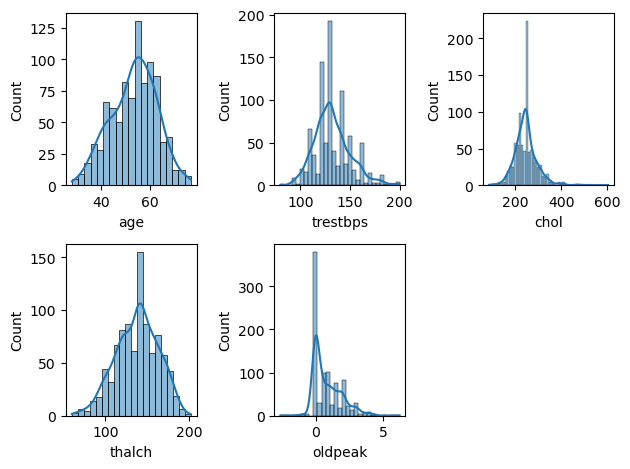

In [23]:
def plotting(var,num):
    plt.subplot(2,3,num)
    sns.histplot(df[var],kde = True)
    
plotting('age',1)
plotting('trestbps',2)
plotting('chol',3)
plotting('thalch',4)
plotting('oldpeak',5)

plt.tight_layout()

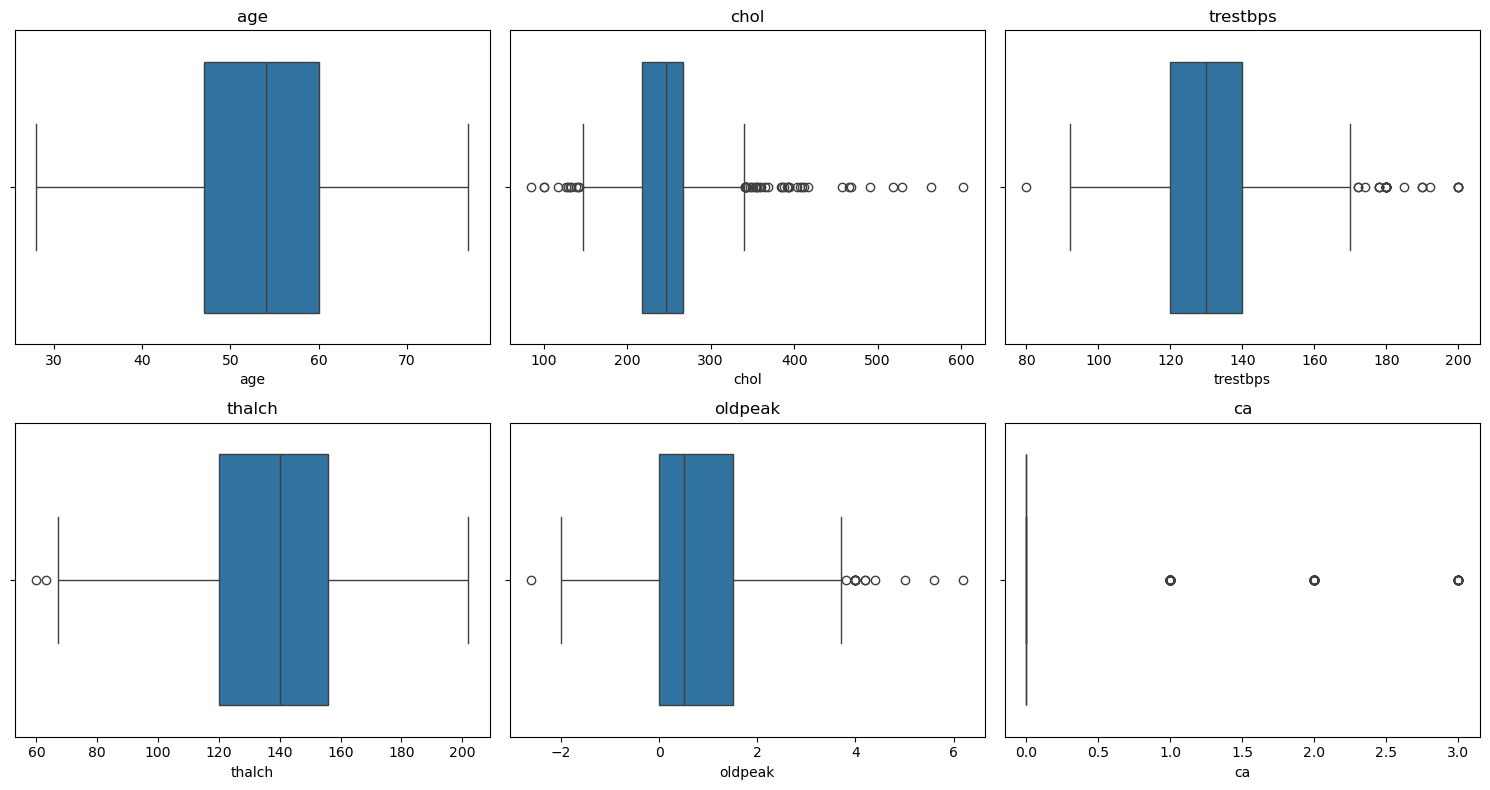

In [24]:
numerical_cols = ['age', 'chol', 'trestbps', 'thalch', 'oldpeak', 'ca']

plt.figure(figsize=(15, 8))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

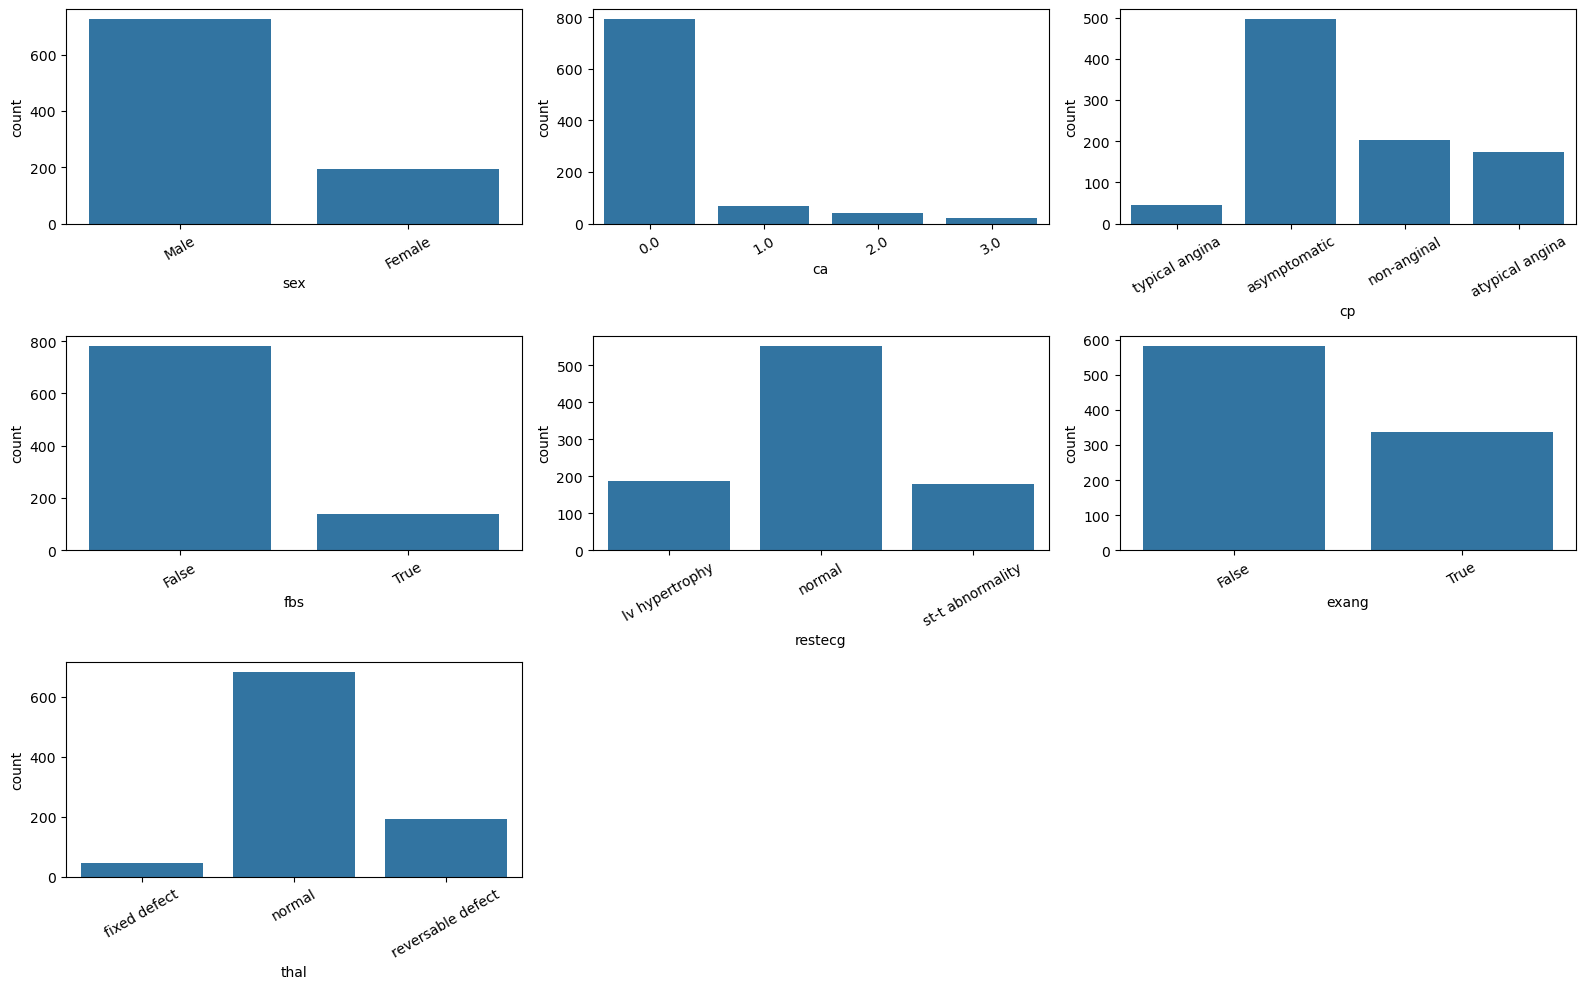

In [25]:
categorical_cols = ['sex', 'ca', 'cp', 'fbs', 'restecg', 'exang', 'thal']

plt.figure(figsize=(16, 10))

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(3, 3, i)
    sns.countplot(x=col, data=df)
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

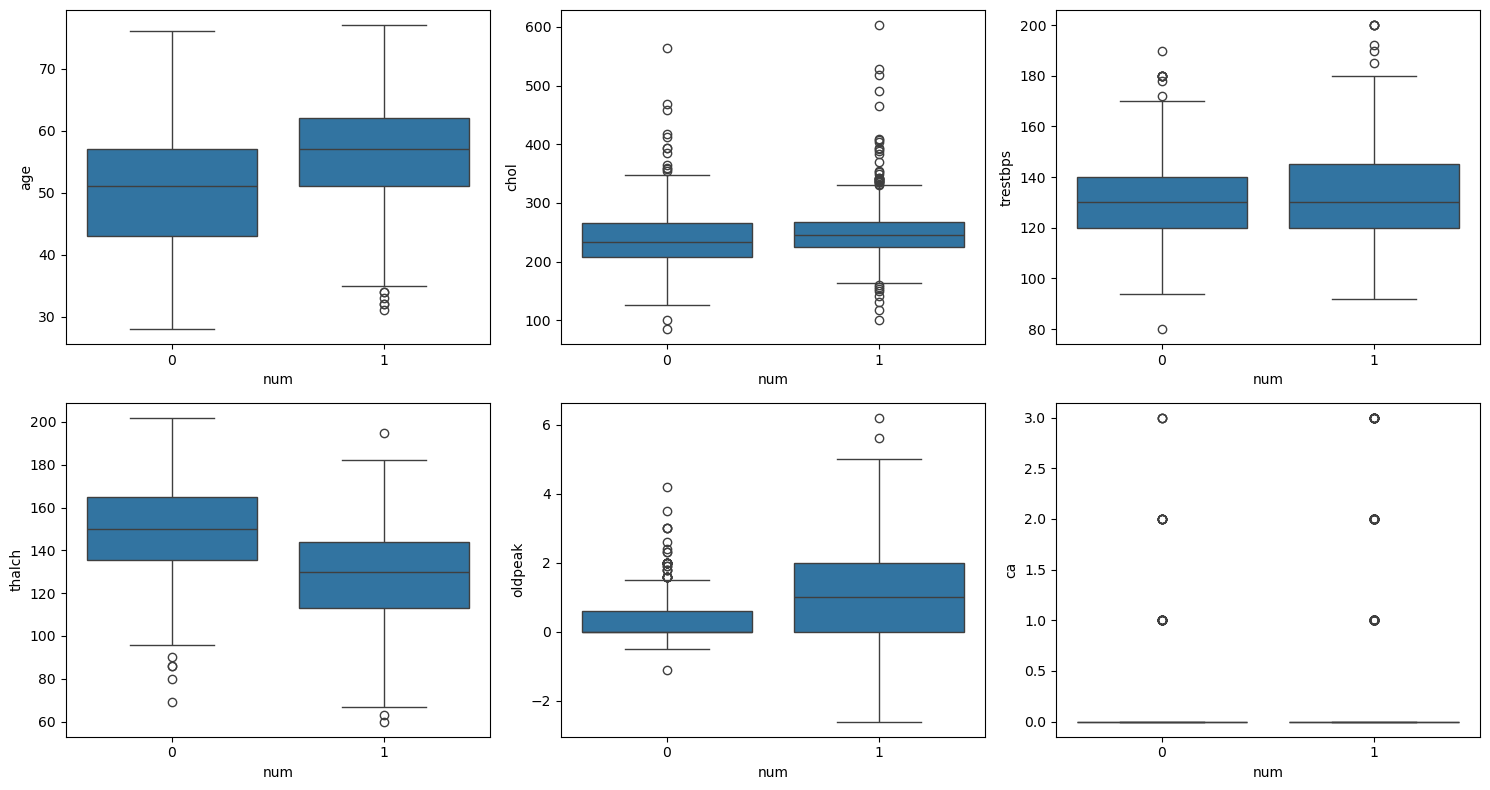

In [26]:
plt.figure(figsize=(15,8))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2,3,i)
    sns.boxplot(data=df, x='num', y=col)

plt.tight_layout()
plt.show()

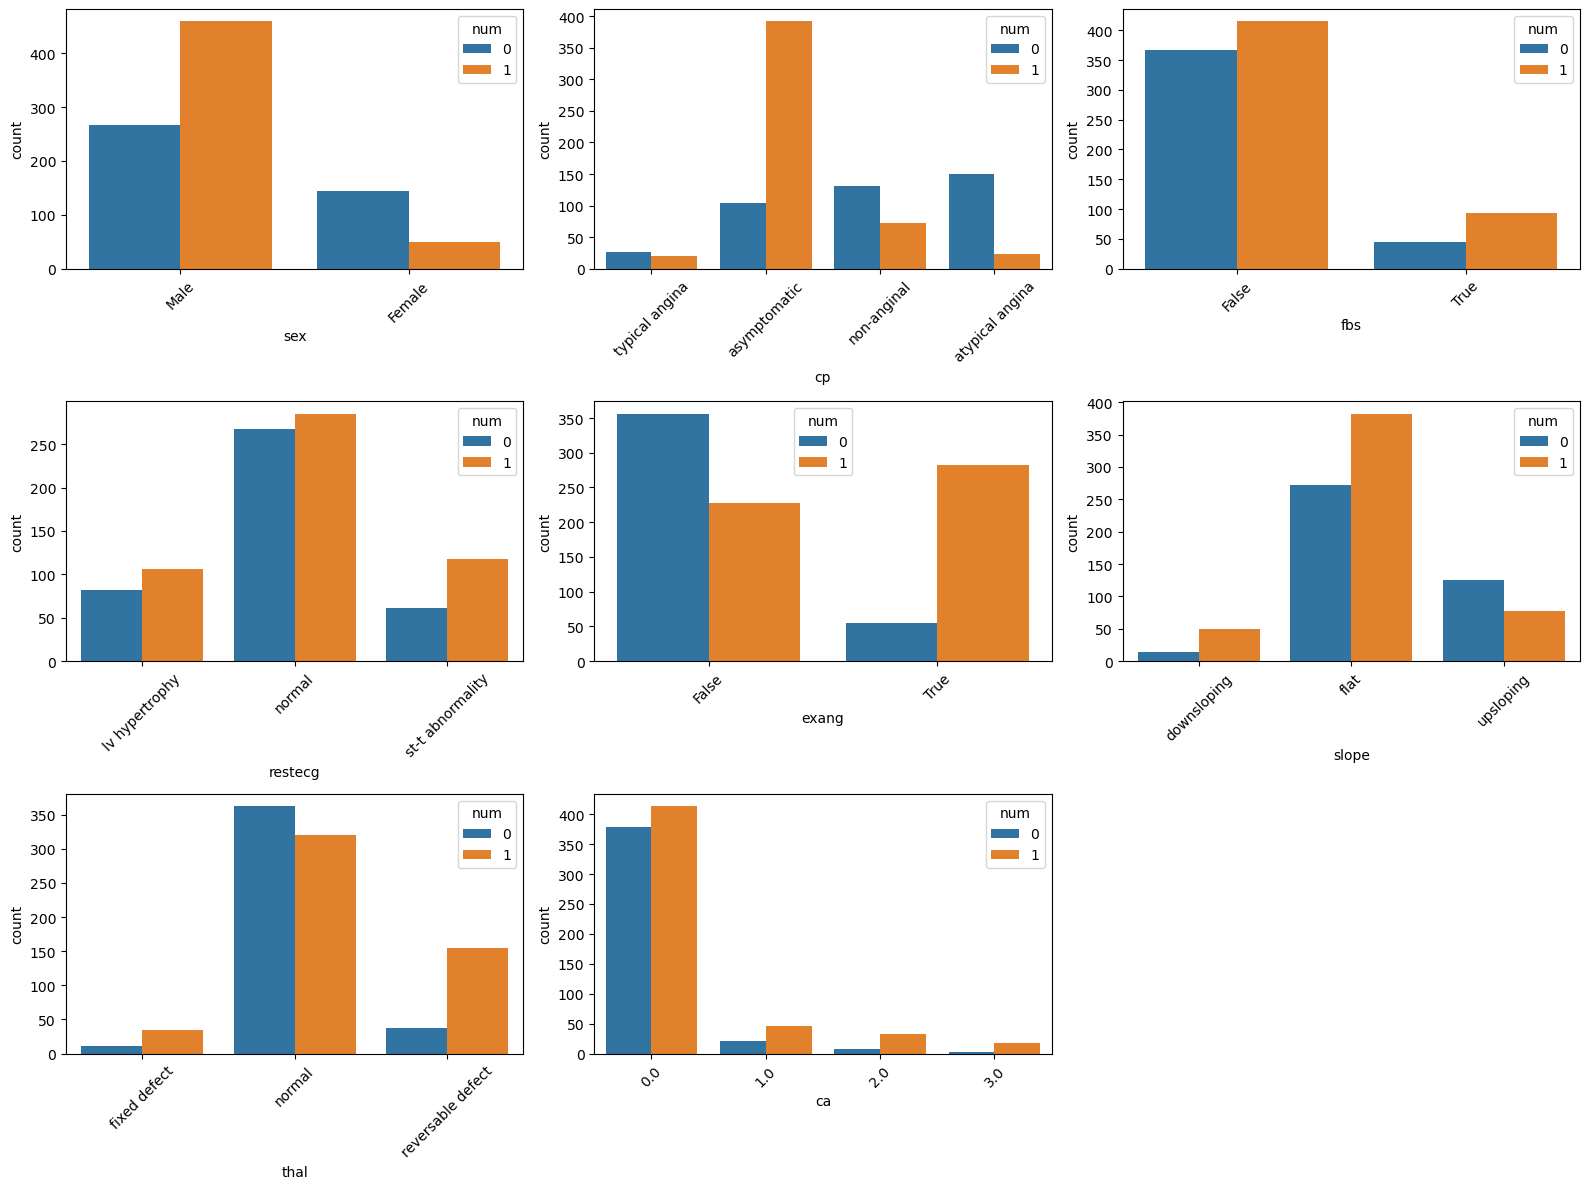

In [27]:
categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal', 'ca']

plt.figure(figsize=(16,12))

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(3,3,i)
    sns.countplot(data=df, x=col, hue='num')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

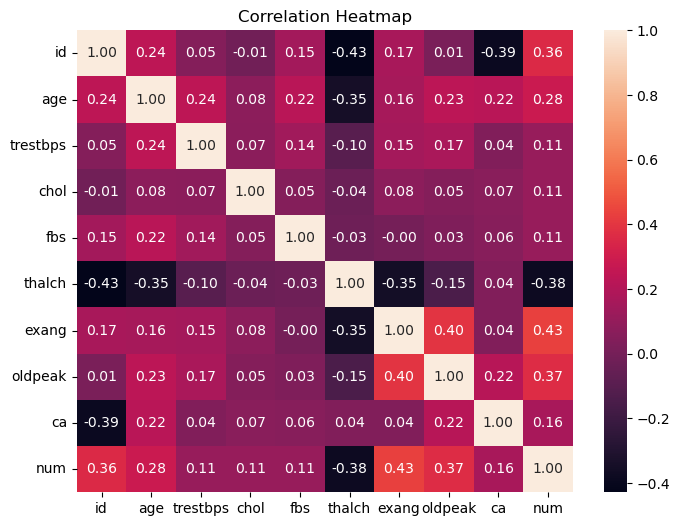

In [28]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f')

plt.title("Correlation Heatmap")
plt.show()

In [29]:
from sklearn.preprocessing import LabelEncoder

label = LabelEncoder()

for col in ['sex', 'fbs', 'exang']:
    df[col] = label.fit_transform(df[col])

df = pd.get_dummies(df, columns=['cp', 'restecg', 'slope', 'thal'], drop_first=True)

In [30]:
df.head()

,id,age,sex,dataset,trestbps,chol,fbs,thalch,exang,oldpeak,...,num,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_normal,restecg_st-t abnormality,slope_flat,slope_upsloping,thal_normal,thal_reversable defect
0,1,63,1,Cleveland,145.0,233.0,1,150.0,0,2.3,...,0,False,False,True,False,False,False,False,False,False
1,2,67,1,Cleveland,160.0,286.0,0,108.0,1,1.5,...,1,False,False,False,False,False,True,False,True,False
2,3,67,1,Cleveland,120.0,229.0,0,129.0,1,2.6,...,1,False,False,False,False,False,True,False,False,True
3,4,37,1,Cleveland,130.0,250.0,0,187.0,0,3.5,...,0,False,True,False,True,False,False,False,True,False
4,5,41,0,Cleveland,130.0,204.0,0,172.0,0,1.4,...,0,True,False,False,False,False,False,True,True,False


In [31]:
df.drop(columns=['id','dataset'], inplace=True)


In [32]:
df


,age,sex,trestbps,chol,fbs,thalch,exang,oldpeak,ca,num,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_normal,restecg_st-t abnormality,slope_flat,slope_upsloping,thal_normal,thal_reversable defect
0,63,1,145.0,233.0,1,150.0,0,2.3,0.0,0,False,False,True,False,False,False,False,False,False
1,67,1,160.0,286.0,0,108.0,1,1.5,3.0,1,False,False,False,False,False,True,False,True,False
2,67,1,120.0,229.0,0,129.0,1,2.6,2.0,1,False,False,False,False,False,True,False,False,True
3,37,1,130.0,250.0,0,187.0,0,3.5,0.0,0,False,True,False,True,False,False,False,True,False
4,41,0,130.0,204.0,0,172.0,0,1.4,0.0,0,True,False,False,False,False,False,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,54,0,127.0,333.0,1,154.0,0,0.0,0.0,1,False,False,False,False,True,True,False,True,False
916,62,1,130.0,139.0,0,140.0,0,0.5,0.0,0,False,False,True,False,True,True,False,True,False
917,55,1,122.0,223.0,1,100.0,0,0.0,0.0,1,False,False,False,False,True,True,False,False,False
918,58,1,130.0,385.0,1,140.0,0,0.5,0.0,0,False,False,False,False,False,True,False,True,False


In [33]:
df = df.astype(int)

In [34]:
df

,age,sex,trestbps,chol,fbs,thalch,exang,oldpeak,ca,num,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_normal,restecg_st-t abnormality,slope_flat,slope_upsloping,thal_normal,thal_reversable defect
0,63,1,145,233,1,150,0,2,0,0,0,0,1,0,0,0,0,0,0
1,67,1,160,286,0,108,1,1,3,1,0,0,0,0,0,1,0,1,0
2,67,1,120,229,0,129,1,2,2,1,0,0,0,0,0,1,0,0,1
3,37,1,130,250,0,187,0,3,0,0,0,1,0,1,0,0,0,1,0
4,41,0,130,204,0,172,0,1,0,0,1,0,0,0,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,54,0,127,333,1,154,0,0,0,1,0,0,0,0,1,1,0,1,0
916,62,1,130,139,0,140,0,0,0,0,0,0,1,0,1,1,0,1,0
917,55,1,122,223,1,100,0,0,0,1,0,0,0,0,1,1,0,0,0
918,58,1,130,385,1,140,0,0,0,0,0,0,0,0,0,1,0,1,0


##### Outliers Handling

In [35]:
Q1 = df['chol'].quantile(0.25)
Q3 = df['chol'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

chol_outliers = df[(df['chol'] < lower) | (df['chol'] > upper)]


print("Number of outliers:", len(chol_outliers))

print("Minimum outlier:", chol_outliers['chol'].min())
print("Maximum outlier:", chol_outliers['chol'].max())


print(chol_outliers['num'].value_counts())

Number of outliers: 47
Minimum outlier: 85
Maximum outlier: 603
num
1    25
0    22
Name: count, dtype: int64


In [36]:
Q1 = df['trestbps'].quantile(0.25)
Q3 = df['trestbps'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR


trestbps_outliers = df[(df['trestbps'] < lower) | (df['trestbps'] > upper)]

print("Number of outliers:", len(trestbps_outliers))


print("Minimum outlier value:", trestbps_outliers['trestbps'].min())
print("Maximum outlier value:", trestbps_outliers['trestbps'].max())

print(trestbps_outliers['num'].value_counts())


Number of outliers: 27
Minimum outlier value: 80
Maximum outlier value: 200
num
1    17
0    10
Name: count, dtype: int64


In [37]:
Q1 = df['oldpeak'].quantile(0.25)
Q3 = df['oldpeak'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

oldpeak_outliers = df[(df['oldpeak'] < lower) | (df['oldpeak'] > upper)]

print("Number of outliers:", len(oldpeak_outliers))

print("Minimum outlier value:", oldpeak_outliers['oldpeak'].min())
print("Maximum outlier value:", oldpeak_outliers['oldpeak'].max())

print(oldpeak_outliers['num'].value_counts())

Number of outliers: 58
Minimum outlier value: -2
Maximum outlier value: 6
num
1    53
0     5
Name: count, dtype: int64


In [38]:
from sklearn.preprocessing import StandardScaler

df_scaled = df.copy()

num_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']

scaler = StandardScaler()

df_scaled[num_cols] = scaler.fit_transform(df_scaled[num_cols])

df_scaled.head()

,age,sex,trestbps,chol,fbs,thalch,exang,oldpeak,ca,num,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_normal,restecg_st-t abnormality,slope_flat,slope_upsloping,thal_normal,thal_reversable defect
0,1.007386,1,0.717687,-0.245232,1,0.489727,0,1.326348,0,0,0,0,1,0,0,0,0,0,0
1,1.432034,1,1.554747,0.777126,0,-1.181478,1,0.323686,3,1,0,0,0,0,0,1,0,1,0
2,1.432034,1,-0.677412,-0.322391,0,-0.345875,1,1.326348,2,1,0,0,0,0,0,1,0,0,1
3,-1.752828,1,-0.119372,0.082694,0,1.961979,0,2.329010,0,0,0,1,0,1,0,0,0,1,0
4,-1.328180,0,-0.119372,-0.804635,0,1.365120,0,0.323686,0,0,1,0,0,0,0,0,1,1,0


##### Train-Test-Split

In [39]:
from sklearn.model_selection import train_test_split


In [40]:
x = df_scaled.drop('num', axis = 1)
y = df_scaled['num']

In [41]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = .20, random_state = 42)

##### Import Models

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

In [43]:
models = {
    "Logistic Regression": LogisticRegression(max_iter = 1000,random_state = 42),
    "Decision Tree": DecisionTreeClassifier(random_state = 42),
    "Random Forest": RandomForestClassifier(random_state = 42),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(random_state = 42),
    "XGBoost": XGBClassifier(random_state= 42)
}

##### Trained models with cross validation

In [44]:
from sklearn.model_selection import cross_validate

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        x_train,
        y_train,
        cv=5,
        scoring=scoring
    )

    results.append({
        "Model": name,
        "Accuracy": scores['test_accuracy'].mean(),
        "Precision": scores['test_precision'].mean(),
        "Recall": scores['test_recall'].mean(),
        "F1 Score": scores['test_f1'].mean(),
        "ROC-AUC": scores['test_roc_auc'].mean()
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values(by="F1 Score", ascending=False))

                 Model  Accuracy  Precision  Recall  F1 Score   ROC-AUC
4                  SVM  0.811151   0.801824  0.8675  0.832676  0.870349
0  Logistic Regression  0.807088   0.822354  0.8225  0.821854  0.879344
2        Random Forest  0.792113   0.797582  0.8275  0.811841  0.863879
3                  KNN  0.777156   0.776323  0.8300  0.802089  0.836331
5              XGBoost  0.771769   0.786312  0.7975  0.790175  0.847356
1        Decision Tree  0.731017   0.751612  0.7575  0.753579  0.728421


##### Model tunning

In [45]:
from sklearn.model_selection import GridSearchCV

In [46]:
model_svm = SVC(probability= True, random_state=42)

param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

grid_svm = GridSearchCV(
    estimator= model_svm,
    param_grid=param_grid,
    cv = 5, 
    scoring='f1', 
    n_jobs=1
)

grid_svm.fit(x_train, y_train)

print("Best Parameters", grid_svm.best_params_)
print("Best f1 score:", grid_svm.best_score_)

Best Parameters {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best f1 score: 0.8326757410913729


In [47]:
model_lr = LogisticRegression(max_iter = 1000, random_state=42)


param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs'],
    'penalty': ['l2']
}

grid_lr = GridSearchCV(
    estimator=model_lr,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_lr.fit(x_train, y_train)

print("Best Parameters:", grid_lr.best_params_)
print("Best F1 Score:", grid_lr.best_score_)

Best Parameters: {'C': 1, 'penalty': 'l2', 'solver': 'liblinear'}
Best F1 Score: 0.8218535621536972


In [48]:
model_rf = RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'max_features': ['sqrt', 'log2']
}

grid_rf = GridSearchCV(
    estimator=model_rf,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_rf.fit(x_train, y_train)

print("Best Parameters:", grid_rf.best_params_)
print("Best F1 Score:", grid_rf.best_score_)

Best Parameters: {'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 300}
Best F1 Score: 0.824485540882695


##### Test on tunned Models

In [49]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

model_svm_test = grid_svm.best_estimator_

y_pred = model_svm_test.predict(x_test)
y_prob = model_svm_test.predict_proba(x_test)[:,1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

Accuracy : 0.8532608695652174
Precision: 0.8660714285714286
Recall   : 0.8899082568807339
F1 Score : 0.8778280542986425
ROC-AUC  : 0.9026299694189602


In [50]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

model_lr_test = grid_lr.best_estimator_

y_pred = model_lr_test.predict(x_test)
y_prob = model_lr_test.predict_proba(x_test)[:,1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

Accuracy : 0.8206521739130435
Precision: 0.8584905660377359
Recall   : 0.8348623853211009
F1 Score : 0.8465116279069768
ROC-AUC  : 0.8927217125382263


In [51]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

model_rf_test = grid_rf.best_estimator_

y_pred = model_rf_test.predict(x_test)
y_prob = model_rf_test.predict_proba(x_test)[:,1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

Accuracy : 0.8641304347826086
Precision: 0.8888888888888888
Recall   : 0.8807339449541285
F1 Score : 0.8847926267281107
ROC-AUC  : 0.9014067278287462
